# Khám phá dữ liệu và kiểm tra chất lượng

EDA chỉ đọc 12 CSV PRSA theo trạm: không điền missing, không tạo đặc trưng huấn luyện và không sửa dữ liệu gốc. Theo proposal, mục tiêu dự kiến là PM2.5 của cùng trạm ở giờ kế tiếp (t+1). Các CSV OHLCV và ảnh JPG ở cấp `data/raw/` không thuộc bộ PRSA nên không được nạp.

## 1. Nạp dữ liệu và kiểm tra cấu trúc

Tự tìm thư mục gốc từ working directory hoặc các thư mục cha để notebook chạy được từ repository root hoặc `notebooks/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

data_dir = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    possible = candidate / "data" / "raw" / "PRSA_Data_20130301-20170228"
    if possible.is_dir():
        data_dir = possible
        project_root = candidate
        break

if data_dir is None:
    raise FileNotFoundError("Không tìm thấy thư mục CSV PRSA. Hãy chạy notebook bên trong repository.")

csv_paths = sorted(data_dir.glob("PRSA_Data_*_20130301-20170228.csv"))
if len(csv_paths) != 12:
    raise ValueError(f"Cần đúng 12 CSV PRSA, tìm thấy {len(csv_paths)} tại {data_dir}")

frames = []
for path in csv_paths:
    frame = pd.read_csv(path, na_values=["NA"])
    frame["source_file"] = path.name
    frames.append(frame)
df = pd.concat(frames, ignore_index=True)

required_columns = {
    "No", "year", "month", "day", "hour", "PM2.5", "PM10", "SO2", "NO2",
    "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM", "station"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Thiếu các cột bắt buộc: {sorted(missing_columns)}")

df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]], errors="coerce")
df = df.sort_values(["station", "datetime"]).reset_index(drop=True)

print(f"Project root: {project_root}")
print(f"Số tệp: {len(csv_paths)} | Kích thước gộp: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print(f"Các trạm: {sorted(df['station'].dropna().unique())}")
print(f"Khoảng thời gian: {df['datetime'].min()} → {df['datetime'].max()}")
display(df.head())
display(df.dtypes.rename("dtype").to_frame())

Project root: c:\Users\ASUS TUF\Documents\GitHub\sgu_finalproject_machinelearning_2026-2027
Số tệp: 12 | Kích thước gộp: 420,768 dòng × 20 cột
Các trạm: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
Khoảng thời gian: 2013-03-01 00:00:00 → 2017-02-28 23:00:00


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,source_file,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,PRSA_Data_Aotizhongxin_20130301-20170228.csv,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,PRSA_Data_Aotizhongxin_20130301-20170228.csv,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,PRSA_Data_Aotizhongxin_20130301-20170228.csv,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,PRSA_Data_Aotizhongxin_20130301-20170228.csv,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,PRSA_Data_Aotizhongxin_20130301-20170228.csv,2013-03-01 04:00:00


,dtype
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64


## 2. Chất lượng và tính liên tục của dữ liệu

Kiểm tra số dòng, số timestamp duy nhất, timestamp trùng/không hợp lệ và số giờ khuyết theo trạm. Thống kê missing bao gồm riêng target PM2.5; chưa impute hoặc loại dòng.

In [2]:
expected_start = pd.Timestamp("2013-03-01 00:00:00")
expected_end = pd.Timestamp("2017-02-28 23:00:00")
expected_hours = pd.date_range(expected_start, expected_end, freq="h")

time_checks = []
for station, group in df.groupby("station", sort=True):
    valid_times = group["datetime"].dropna()
    unique_times = pd.DatetimeIndex(valid_times.unique()).sort_values()
    time_checks.append({
        "station": station,
        "rows": len(group),
        "unique_timestamps": len(unique_times),
        "duplicate_timestamps": int(valid_times.duplicated().sum()),
        "invalid_timestamps": int(group["datetime"].isna().sum()),
        "missing_hours_in_expected_range": len(expected_hours.difference(unique_times)),
        "start": unique_times.min() if len(unique_times) else pd.NaT,
        "end": unique_times.max() if len(unique_times) else pd.NaT,
    })
time_checks = pd.DataFrame(time_checks).set_index("station")
display(time_checks)
print(f"Số giờ kỳ vọng mỗi trạm: {len(expected_hours):,}")

analysis_columns = [column for column in df.columns if column != "source_file"]
missing_summary = pd.DataFrame({
    "missing_count": df[analysis_columns].isna().sum(),
    "missing_percent": df[analysis_columns].isna().mean().mul(100),
}).sort_values("missing_percent", ascending=False)
display(missing_summary)

missing_by_station = df.groupby("station")[analysis_columns].apply(
    lambda group: group.isna().mean().mul(100)
)
display(missing_by_station["PM2.5"].rename("PM2.5_missing_percent").to_frame())
display(missing_by_station.T)

,rows,unique_timestamps,duplicate_timestamps,invalid_timestamps,missing_hours_in_expected_range,start,end
station,,,,,,,
Aotizhongxin,35064,35064,0,0,0,2013-03-01,2017-02-28 23:00:00
Changping,35064,35064,0,0,0,2013-03-01,2017-02-28 23:00:00
Dingling,35064,35064,0,0,0,2013-03-01,2017-02-28 23:00:00
Dongsi,35064,35064,0,0,0,2013-03-01,2017-02-28 23:00:00
Guanyuan,35064,35064,0,0,0,2013-03-01,2017-02-28 23:00:00
Gucheng,35064,35064,0,0,0,2013-03-01,2017-02-28 23:00:00
Huairou,35064,35064,0,0,0,2013-03-01,2017-02-28 23:00:00
Nongzhanguan,35064,35064,0,0,0,2013-03-01,2017-02-28 23:00:00
Shunyi,35064,35064,0,0,0,2013-03-01,2017-02-28 23:00:00


Số giờ kỳ vọng mỗi trạm: 35,064


,missing_count,missing_percent
CO,20701,4.919813
O3,13277,3.155421
NO2,12116,2.879497
SO2,9021,2.143937
PM2.5,8739,2.076916
PM10,6449,1.532674
wd,1822,0.433018
DEWP,403,0.095777
TEMP,398,0.094589
PRES,393,0.093401


,PM2.5_missing_percent
station,
Aotizhongxin,2.638033
Changping,2.207392
Dingling,2.221652
Dongsi,2.138946
Guanyuan,1.756788
Gucheng,1.842345
Huairou,2.717887
Nongzhanguan,1.791011
Shunyi,2.603810


station,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
No,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
year,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
month,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
day,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
hour,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
PM2.5,2.638033,2.207392,2.221652,2.138946,1.756788,1.842345,2.717887,1.791011,2.603810,1.930755,1.089436,1.984942
PM10,2.047684,1.659822,1.870865,1.577116,1.223477,1.086585,2.215948,1.254848,1.562856,1.702601,0.809948,1.380333
SO2,2.666553,1.791011,2.081907,1.890828,1.351814,1.445927,2.794889,1.271960,3.696099,3.188455,1.639859,1.907940
NO2,2.917522,1.902236,3.519279,4.565937,1.879420,1.905088,4.674310,1.973534,3.892882,2.121834,3.051563,2.150354
CO,5.065024,4.337782,5.738079,9.117614,4.999430,3.995551,4.055441,3.439425,6.211499,3.211271,5.167693,3.698950


## 3. Phân bố PM2.5 và so sánh giữa trạm

Báo cáo các phân vị của PM2.5 và vẽ histogram/boxplot. Không loại bỏ giá trị cao chỉ vì chúng là ngoại lệ trên biểu đồ; cần xác minh ngữ cảnh trước khi kết luận.

,count,mean,std,min,25%,50%,75%,95%,99%,max
station,,,,,,,,,,
Aotizhongxin,34139.0,82.773611,82.135694,3.0,22.0,58.0,114.00,248.0,377.00,898.0
Changping,34290.0,71.099743,72.326926,2.0,18.0,46.0,100.00,222.0,322.00,882.0
Dingling,34285.0,65.989497,72.267723,3.0,14.0,41.0,93.00,215.0,331.16,881.0
Dongsi,34314.0,86.194297,86.575127,3.0,22.0,61.0,119.00,260.0,396.00,737.0
Guanyuan,34448.0,82.933372,80.933497,2.0,23.0,59.0,115.00,243.0,377.00,680.0
Gucheng,34418.0,83.852089,82.796445,2.0,24.0,60.0,115.75,247.0,381.00,770.0
Huairou,34111.0,69.626367,71.224916,2.0,17.0,47.0,98.00,216.0,321.00,762.0
Nongzhanguan,34436.0,84.838483,86.225344,2.0,22.0,59.0,116.00,260.0,394.00,844.0
Shunyi,34151.0,79.491602,81.231739,2.0,19.0,55.0,112.00,242.0,373.50,941.0


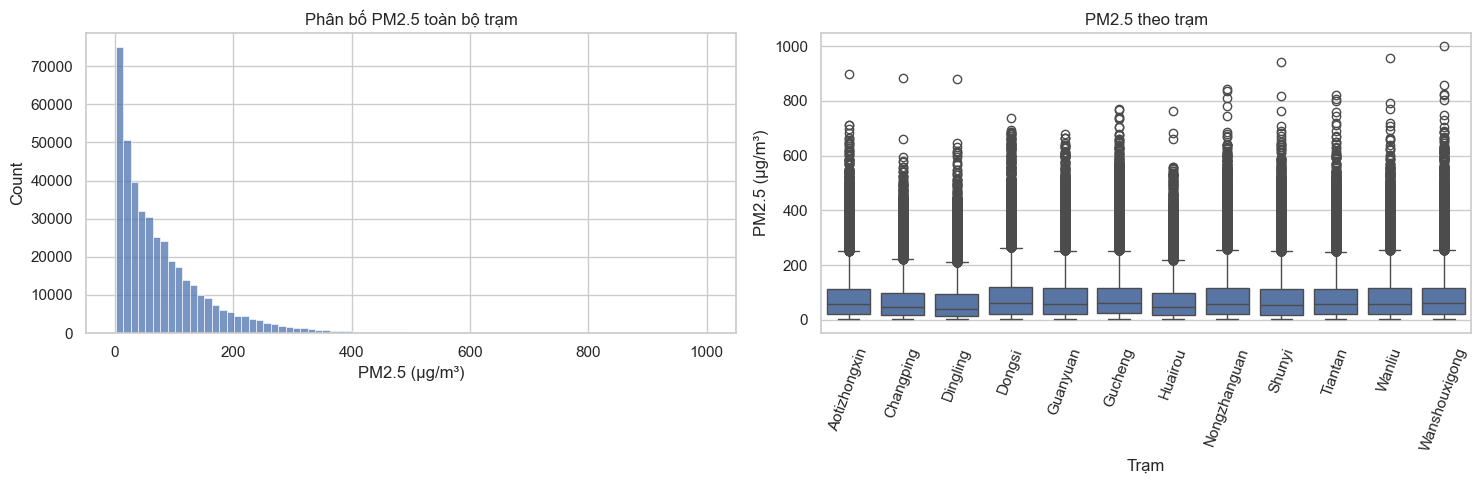

In [3]:
pm25_summary = df.groupby("station")["PM2.5"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
display(pm25_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(data=df, x="PM2.5", bins=80, ax=axes[0])
axes[0].set(title="Phân bố PM2.5 toàn bộ trạm", xlabel="PM2.5 (µg/m³)")
sns.boxplot(data=df, x="station", y="PM2.5", ax=axes[1])
axes[1].set(title="PM2.5 theo trạm", xlabel="Trạm", ylabel="PM2.5 (µg/m³)")
axes[1].tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

## 4. Xu hướng theo thời gian, giờ và mùa

Dùng trung bình nhóm để trực quan hóa xu hướng mà không vẽ từng điểm trong hơn 400 nghìn dòng. Mùa được gom theo tháng khí tượng học.

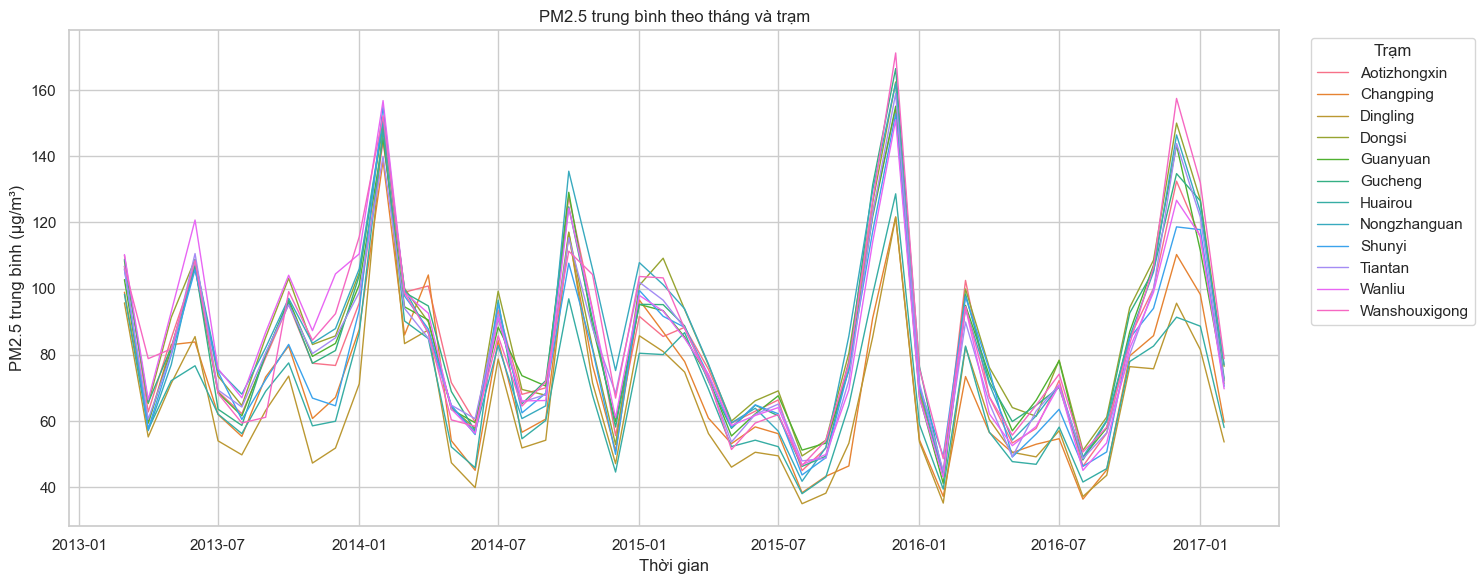

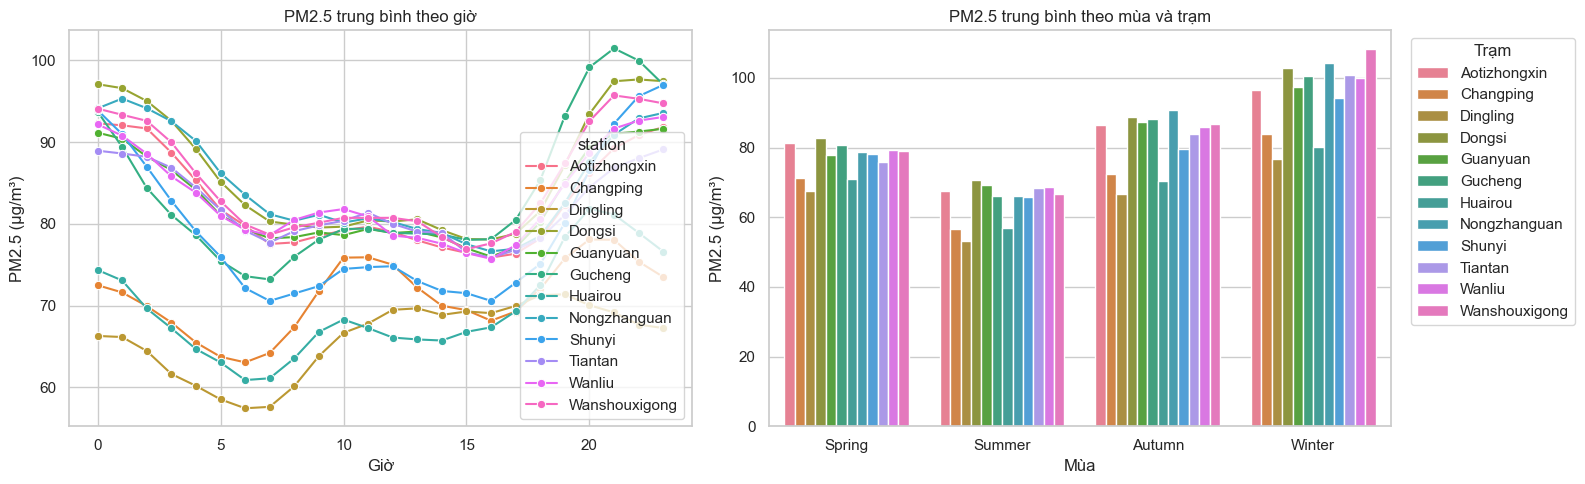

season,Spring,Summer,Autumn,Winter
station,,,,
Aotizhongxin,81.230224,67.551824,86.589328,96.419900
Changping,71.371394,56.672716,72.452857,83.993840
Dingling,67.664431,53.186931,66.731674,76.666184
Dongsi,82.651255,70.556540,88.732503,102.806415
Guanyuan,77.731135,69.244535,87.399133,97.474355
Gucheng,80.735583,66.203590,88.176659,100.564282
Huairou,71.062881,56.935526,70.411049,80.279884
Nongzhanguan,78.641032,66.192782,90.745252,104.339749
Shunyi,78.197356,65.750264,79.696101,94.302063


In [4]:
monthly_pm25 = (
    df.dropna(subset=["datetime"])
    .set_index("datetime")
    .groupby("station")["PM2.5"]
    .resample("MS")
    .mean()
    .rename("PM2.5")
    .reset_index()
)
plt.figure(figsize=(15, 6))
sns.lineplot(data=monthly_pm25, x="datetime", y="PM2.5", hue="station", linewidth=1)
plt.title("PM2.5 trung bình theo tháng và trạm")
plt.xlabel("Thời gian")
plt.ylabel("PM2.5 trung bình (µg/m³)")
plt.legend(title="Trạm", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

hourly_pm25 = df.groupby(["station", "hour"], as_index=False)["PM2.5"].mean()
month_to_season = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
df["season"] = df["month"].map(month_to_season)
seasonal_pm25 = df.groupby(["station", "season"], as_index=False)["PM2.5"].mean()
season_order = ["Spring", "Summer", "Autumn", "Winter"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.lineplot(data=hourly_pm25, x="hour", y="PM2.5", hue="station", marker="o", ax=axes[0])
axes[0].set(title="PM2.5 trung bình theo giờ", xlabel="Giờ", ylabel="PM2.5 (µg/m³)")
sns.barplot(data=seasonal_pm25, x="season", y="PM2.5", hue="station", order=season_order, ax=axes[1])
axes[1].set(title="PM2.5 trung bình theo mùa và trạm", xlabel="Mùa", ylabel="PM2.5 (µg/m³)")
axes[1].legend(title="Trạm", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
display(seasonal_pm25.pivot(index="station", columns="season", values="PM2.5").reindex(columns=season_order))

## 5. Tương quan và các phát hiện cần ghi nhận

Tương quan Pearson thể hiện liên hệ tuyến tính, không chứng minh quan hệ nhân quả. Cột `No` là số thứ tự dòng nên không đưa vào ma trận.

,PM2.5
PM2.5,1.000000
PM10,0.884380
CO,0.789998
NO2,0.666948
SO2,0.482354
DEWP,0.114656
PRES,0.018566
hour,0.011709
month,0.010438
day,0.003428


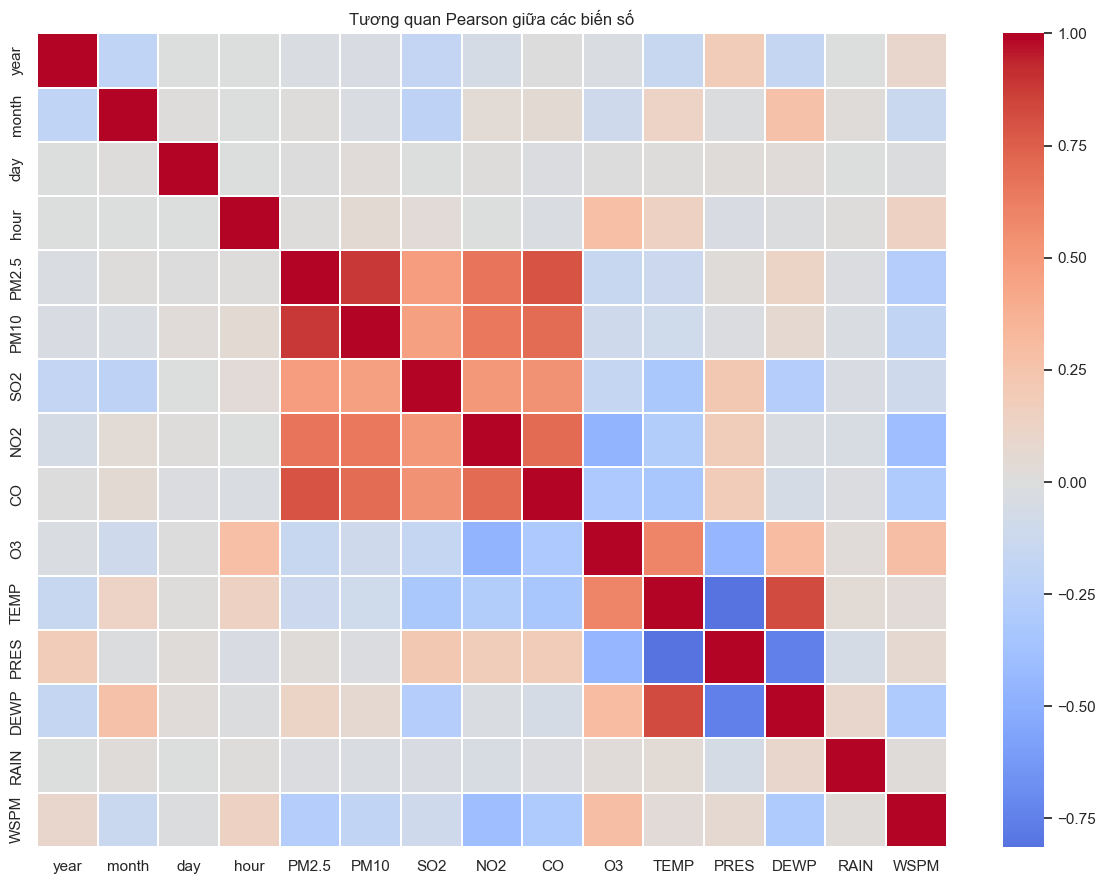

,Giá trị
Số tệp CSV,12.000
Số trạm,12.000
Tổng số dòng,420768.000
Số dòng kỳ vọng (12 × 35.064),420768.000
Dòng trùng station-datetime,0.000
Timestamp không parse được,0.000
PM2.5 missing (%),2.077
PM2.5 nhỏ hơn 0,0.000
Tổng số ô missing,74027.000


Ghi chú cho bước tiếp theo:
- Không dùng dòng thiếu PM2.5 làm target huấn luyện hoặc đánh giá.
- Chọn cách xử lý missing của feature theo thời gian/trạm; thống kê imputation chỉ fit trên train.
- Lag/rolling cho dự đoán t+1 phải chỉ dùng quá khứ và tính riêng theo trạm.
- Không loại PM2.5 cao chỉ dựa trên boxplot; cần xác minh đó là lỗi đo hay sự kiện thực tế.


In [5]:
numeric_columns = df.select_dtypes(include="number").columns.drop("No", errors="ignore")
correlation = df[numeric_columns].corr()
display(correlation[["PM2.5"]].sort_values("PM2.5", ascending=False))
plt.figure(figsize=(12, 9))
sns.heatmap(correlation, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Tương quan Pearson giữa các biến số")
plt.tight_layout()
plt.show()

quality_summary = pd.Series({
    "Số tệp CSV": len(csv_paths),
    "Số trạm": df["station"].nunique(),
    "Tổng số dòng": len(df),
    "Số dòng kỳ vọng (12 × 35.064)": 12 * len(expected_hours),
    "Dòng trùng station-datetime": int(df.duplicated(["station", "datetime"]).sum()),
    "Timestamp không parse được": int(df["datetime"].isna().sum()),
    "PM2.5 missing (%)": round(df["PM2.5"].isna().mean() * 100, 3),
    "PM2.5 nhỏ hơn 0": int(df["PM2.5"].lt(0).sum()),
    "Tổng số ô missing": int(df.isna().sum().sum()),
}, name="Giá trị")
display(quality_summary.to_frame())

print("Ghi chú cho bước tiếp theo:")
print("- Không dùng dòng thiếu PM2.5 làm target huấn luyện hoặc đánh giá.")
print("- Chọn cách xử lý missing của feature theo thời gian/trạm; thống kê imputation chỉ fit trên train.")
print("- Lag/rolling cho dự đoán t+1 phải chỉ dùng quá khứ và tính riêng theo trạm.")
print("- Không loại PM2.5 cao chỉ dựa trên boxplot; cần xác minh đó là lỗi đo hay sự kiện thực tế.")

## 6. Save a standardized data copy

This step combines the 12 stations, adds a parsed `datetime`, sorts by station and time, and writes a CSV under `data/processed/`. It does not remove high readings, drop rows with a missing target, or impute missing values. This is a standardized source copy, not model-ready imputed data; fit imputers and scalers on training data only after the chronological split.

In [ ]:
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
processed_path = processed_dir / "beijing_air_quality_standardized.csv"

# Keep source columns, add datetime, and exclude EDA-only helper columns.
standardized_columns = [column for column in df.columns if column not in {"source_file", "season"}]
standardized_df = df[standardized_columns].sort_values(["station", "datetime"]).reset_index(drop=True)
standardized_df.to_csv(processed_path, index=False, date_format="%Y-%m-%d %H:%M:%S")

# Reload the output and verify the data properties we intend to preserve.
saved_df = pd.read_csv(processed_path, na_values=["NA"], parse_dates=["datetime"])
assert len(saved_df) == 12 * len(expected_hours)
assert saved_df["station"].nunique() == 12
assert not saved_df.duplicated(["station", "datetime"]).any()
assert saved_df["datetime"].min() == expected_start
assert saved_df["datetime"].max() == expected_end
assert saved_df["PM2.5"].isna().sum() == df["PM2.5"].isna().sum()
assert saved_df["PM2.5"].eq(999).sum() == df["PM2.5"].eq(999).sum()
assert saved_df.isna().sum().sum() == df[standardized_columns].isna().sum().sum()

print(f"Saved standardized data: {processed_path.relative_to(project_root)}")
print(f"Rows x columns: {saved_df.shape[0]:,} x {saved_df.shape[1]}")
print(f"Missing cells preserved: {int(saved_df.isna().sum().sum()):,}")
print(f"Missing PM2.5 preserved: {int(saved_df['PM2.5'].isna().sum()):,}")
print(f"PM2.5 values >= 500 retained: {int(saved_df['PM2.5'].ge(500).sum()):,}")
print(f"PM2.5 value 999 retained: {int(saved_df['PM2.5'].eq(999).sum())}")